# Setup dell'Ambiente e Gestione del Dataset
In questa cella colleghiamo Google Drive, ci spostiamo nella cartella di lavoro e prepariamo il dataset scompattandolo nello spazio locale di Colab per velocizzare la lettura delle immagini.

In [1]:
from google.colab import drive
import os

# 1. Mount del Drive e posizionamento nella cartella del progetto
drive.mount('/content/drive')
os.chdir('/content/drive/Shareddrives/ML_Project/Data/')

# 2. Copia e scompattamento del dataset nello spazio locale temporaneo di Colab
!cp "./waste_type_identification.zip" "/content/"
!unzip -q "/content/waste_type_identification.zip" -d "/content/dataset/"

print("Dataset caricato e scompattato localmente con successo.")

Mounted at /content/drive
Dataset caricato e scompattato localmente con successo.


# Collegamento dei File Esterni
Utilizziamo il comando %run per caricare in memoria tutto ciò che hai scritto negli altri due notebook. In questo modo, le funzioni get_dataloaders, initial_reset, train_model_decay_lr e plot_metrics saranno immediatamente utilizzabili.

In [2]:
# Importazione magica delle funzioni e delle classi dagli altri notebook
%run "/content/drive/Shareddrives/ML_Project/EfficientNet/Michela/data_augmentation.ipynb"
%run "/content/drive/Shareddrives/ML_Project/EfficientNet/Michela/training_hyperparameters.ipynb"

print("Notebook esterni agganciati e pronti all'uso.")

Notebook esterni agganciati e pronti all'uso.


# Definizione degli Iperparametri Globali
Qui centralizziamo tutte le variabili modificabili. Se vuoi cambiare la configurazione dei tuoi test (griglia di iperparametri), ti basterà modificare esclusivamente i valori in questa cella.

In [4]:
import torch.optim as optim

# =====================================================================
# CONFIGURAZIONE IPERPARAMETRI DEFINITIVI (FASE 1 - FABIO)
# =====================================================================
DATA_DIR = '/content/dataset/waste_type_identification'
BATCH_SIZE = 32
NUM_CLASSES = 8
NUM_EPOCHS = 40
PATIENCE = 5

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001
DROPOUT_RATE = 0.2
TRAINING_LAYERS = 5

# Inizializzazione dei Flussi Dati (Dataloaders)
Invochiamo la funzione contenuta in data_augmentation.ipynb per generare i dizionari di addestramento e validazione strutturati con il campionamento pesato e il wrapper condizionale.

In [5]:
# Generazione dei Dataloaders e recupero dei nomi delle classi
dataloaders, class_names = get_uniform_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    val_size=0.2,
    random_seed=42
)


Dataloader in assetto 'Clean' pronti per il test di controllo.
Rimossi: Variazioni di luminosità, contrasto, sfocatura e distorsione prospettica.


# Calcolo dei Pesi per la Loss Funzionale
Dato che il metodo train_model_decay_lr accetta un parametro opzionale class_weights, estraiamo la distribuzione reale dei target di addestramento per bilanciare il calcolo della Cross Entropy.

In [6]:
import numpy as np
import torch

# Estrazione delle etichette reali del subset di training per calcolare i pesi della loss
train_subset = dataloaders['train'].dataset.subset
train_targets = [train_subset.dataset.targets[i] for i in train_subset.indices]

# Calcolo delle frequenze e inversione dei pesi
class_counts = np.bincount(train_targets, minlength=NUM_CLASSES)
class_weights = 1.0 / class_counts.astype(float)
class_weights_normalization = class_weights / class_weights.sum()

# Conversione in tensore PyTorch
loss_weights_tensor = torch.FloatTensor(class_weights_normalization)
print(f"Pesi calcolati per il bilanciamento della Loss: {loss_weights_tensor}")

Pesi calcolati per il bilanciamento della Loss: tensor([0.1488, 0.0193, 0.0699, 0.1829, 0.1427, 0.0724, 0.1625, 0.2016])


# Inizializzazione della Rete, Ottimizzatore e Scheduler
Prepariamo l'architettura della ResNet-18 e configuriamo il meccanismo di decadimento del Learning Rate. Poiché la funzione nel tuo notebook esegue scheduler.step() senza passare parametri a fine epoca, utilizzeremo uno scheduler basato sul conteggio delle epoche (come StepLR).

In [7]:
# 1. Inizializzazione della rete tramite la nuova funzione modulare del secondo notebook
model = initial_reset(
    num_classes=NUM_CLASSES,
    training_layers=TRAINING_LAYERS,
    dropout_rate=DROPOUT_RATE
)

# 2. Ottimizzatore Adam configurato unicamente sui parametri attivi (requires_grad=True)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 3. SCHEDULER ADATTIVO:
# Tarato con patience=3 per evitare correzioni troppo isteriche sulla nuova architettura
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.1)

print("\n" + "="*65)
print(" MAPPA DELLO STATO DEI GRADIENTI")
print("="*65)

# Iteriamo dinamicamente su tutti i sotto-blocchi di model.features
for idx, block in enumerate(model.features):
    # Verifichiamo se almeno un parametro del blocco richiede l'aggiornamento dei pesi
    requires_grad = any(p.requires_grad for p in block.parameters())
    semaforo = "🟢 TRUE  (Sbloccato)" if requires_grad else "🔴 FALSE (Congelato)"

    # Creiamo delle etichette descrittive per capire cosa fa ogni blocco
    if idx == 0:
        desc = "[Stem Conv - Filtri d'ingresso]"
    elif idx == 8:
        desc = "[Head Conv - Convoluzione finale]"
    else:
        desc = f"[Blocco MBConv - Stage {idx}]"

    # Allineiamo il testo per renderlo perfettamente leggibile a colpo d'occhio
    print(f" model.features[{idx}] {desc:<35} -> {semaforo}")

print("-" * 65)

# Verifichiamo il layer lineare finale del classificatore
clf_linear_grad = model.classifier[1].weight.requires_grad
semaforo_clf = "🟢 TRUE  (Sbloccato)" if clf_linear_grad else "🔴 FALSE (Congelato)"

print(f" model.classifier[1] [FC Layer - Classificatore Finale] -> {semaforo_clf}")
print(f" Tasso di Dropout impostato nella testa:                    -> {model.classifier[0].p}")
print("="*65 + "\n")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 174MB/s]


 MAPPA DELLO STATO DEI GRADIENTI
 model.features[0] [Stem Conv - Filtri d'ingresso]     -> 🔴 FALSE (Congelato)
 model.features[1] [Blocco MBConv - Stage 1]           -> 🔴 FALSE (Congelato)
 model.features[2] [Blocco MBConv - Stage 2]           -> 🔴 FALSE (Congelato)
 model.features[3] [Blocco MBConv - Stage 3]           -> 🔴 FALSE (Congelato)
 model.features[4] [Blocco MBConv - Stage 4]           -> 🟢 TRUE  (Sbloccato)
 model.features[5] [Blocco MBConv - Stage 5]           -> 🟢 TRUE  (Sbloccato)
 model.features[6] [Blocco MBConv - Stage 6]           -> 🟢 TRUE  (Sbloccato)
 model.features[7] [Blocco MBConv - Stage 7]           -> 🟢 TRUE  (Sbloccato)
 model.features[8] [Head Conv - Convoluzione finale]   -> 🟢 TRUE  (Sbloccato)
-----------------------------------------------------------------
 model.classifier[1] [FC Layer - Classificatore Finale] -> 🟢 TRUE  (Sbloccato)
 Tasso di Dropout impostato nella testa:                    -> 0.2



# Esecuzione dell'Addestramento e Visualizzazione delle Metriche
Avviamo il motore di calcolo del secondo notebook e passiamo l'output direttamente alla funzione grafica per valutare visivamente l'andamento delle performance


Epoca 1/40
----------
Train Loss: 0.7154 | Acc: 0.8027 | Bal. Acc: 0.7956
Val Loss: 0.2141 | Acc: 0.9523 | Bal. Acc: 0.9376

Epoca 2/40
----------
Train Loss: 0.2408 | Acc: 0.9334 | Bal. Acc: 0.9219
Val Loss: 0.1456 | Acc: 0.9646 | Bal. Acc: 0.9529

Epoca 3/40
----------
Train Loss: 0.1679 | Acc: 0.9517 | Bal. Acc: 0.9455
Val Loss: 0.1582 | Acc: 0.9620 | Bal. Acc: 0.9498
-> EarlyStopping Counter: 1 su 5

Epoca 4/40
----------
Train Loss: 0.1217 | Acc: 0.9651 | Bal. Acc: 0.9594
Val Loss: 0.1161 | Acc: 0.9720 | Bal. Acc: 0.9612

Epoca 5/40
----------
Train Loss: 0.1012 | Acc: 0.9686 | Bal. Acc: 0.9671
Val Loss: 0.1259 | Acc: 0.9697 | Bal. Acc: 0.9598
-> EarlyStopping Counter: 1 su 5

Epoca 6/40
----------
Train Loss: 0.0757 | Acc: 0.9762 | Bal. Acc: 0.9743
Val Loss: 0.1353 | Acc: 0.9713 | Bal. Acc: 0.9632
-> EarlyStopping Counter: 2 su 5

Epoca 7/40
----------
Train Loss: 0.0710 | Acc: 0.9785 | Bal. Acc: 0.9767
Val Loss: 0.1422 | Acc: 0.9707 | Bal. Acc: 0.9557
Learning Rate decresciuto 

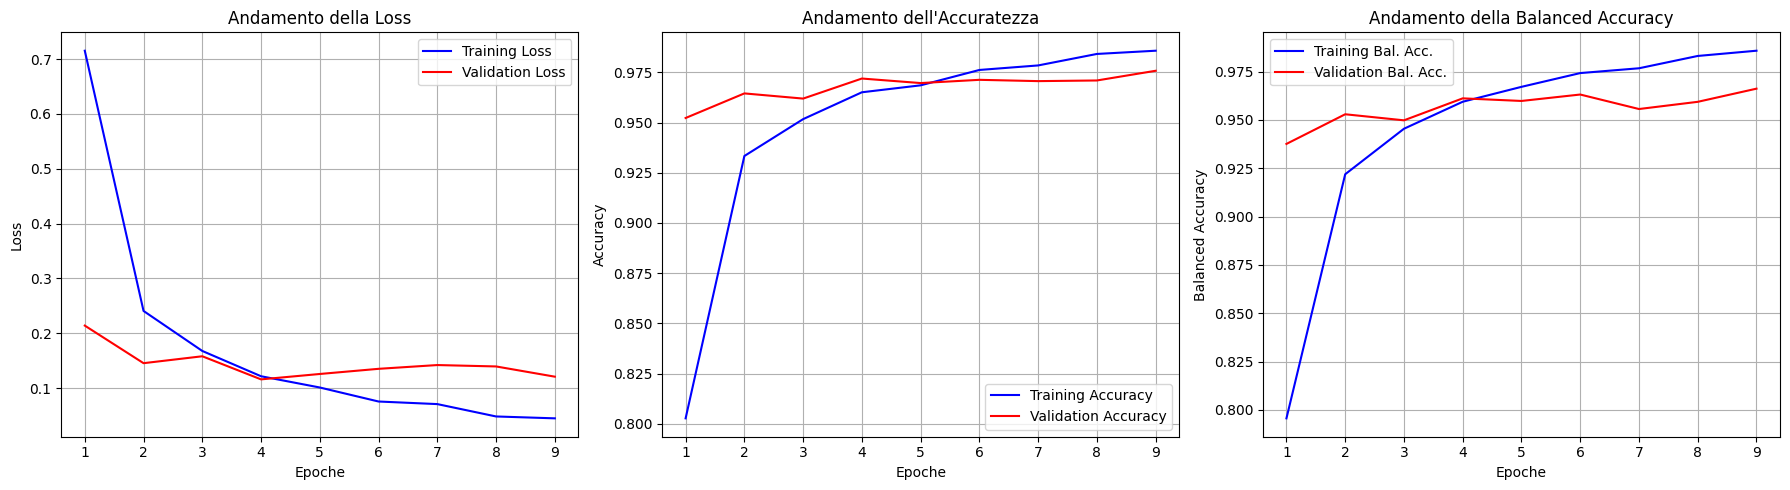

In [8]:
model_addestrato, history = train_model_advanced(
    model=model,
    dataloaders=dataloaders,
    optimizer=optimizer,
    epochs=NUM_EPOCHS,
    scheduler=scheduler,
    class_weights=loss_weights_tensor,
    patience=PATIENCE
)

# Generazione automatica dei grafici a 3 pannelli
plot_metrics(history)

Avvio della valutazione finale sul Validation Set...

================ METRICHE GLOBALI CONSOLIDATE ================
Accuracy Globale: 0.9720
Precision (Macro): 0.9523
F1-Score (Macro):  0.9566

Report dettagliato per categoria merceologica:
                  precision    recall  f1-score   support

         battery       0.96      0.98      0.97       189
        clothing       1.00      0.98      0.99      1461
           glass       0.95      0.97      0.96       402
           metal       0.89      0.94      0.91       154
         organic       0.97      0.99      0.98       197
          papery       0.97      0.96      0.97       388
         plastic       0.92      0.90      0.91       173
undifferentiated       0.96      0.96      0.96       139

        accuracy                           0.97      3103
       macro avg       0.95      0.96      0.96      3103
    weighted avg       0.97      0.97      0.97      3103



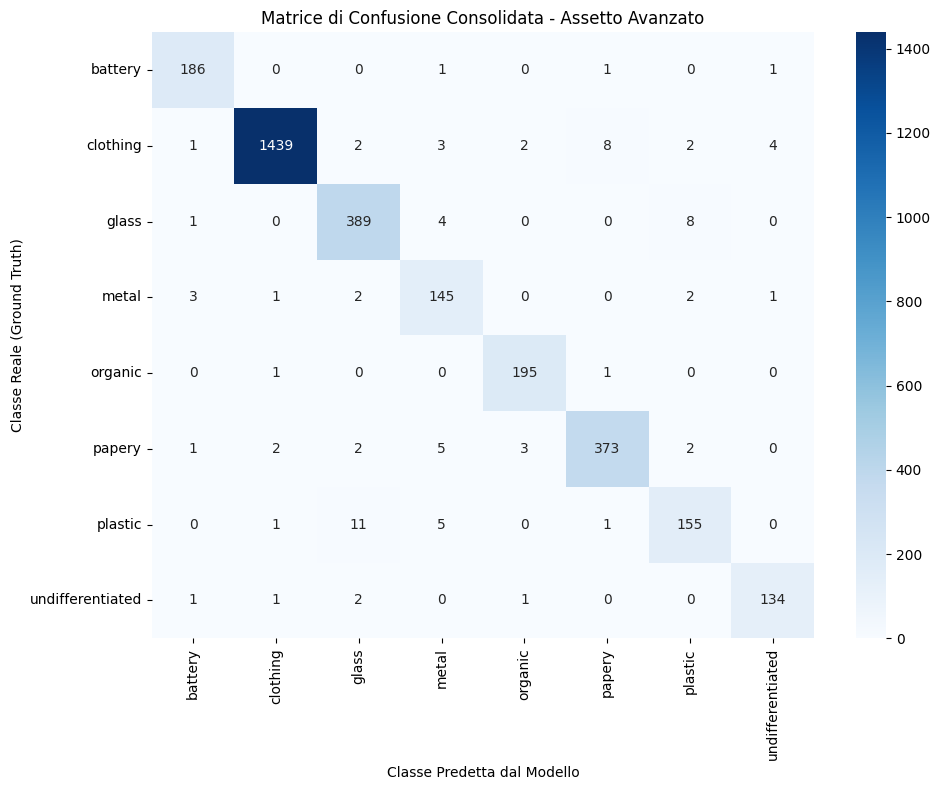

In [9]:
# =====================================================================
# VALUTAZIONE AVANZATA E MATRICE DI CONFUSIONE
# =====================================================================
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, f1_score

print("Avvio della valutazione finale sul Validation Set...")
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# 1. Impostiamo il modello in modalità valutazione (inferenza)
model_addestrato.eval()

all_preds = []
all_labels = []

# Disabilitiamo il calcolo dei gradienti per velocizzare l'esecuzione e risparmiare memoria VRAM
with torch.no_grad():
    for inputs, labels in dataloaders['val']:
        # Trasferiamo i dati sul device corretto (GPU o CPU)
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Passo di forward per ottenere i punteggi logit della rete
        outputs = model_addestrato(inputs)
        _, preds = torch.max(outputs, 1) # Estraiamo l'indice della classe a probabilità massima

        # Sganciamo i tensori dalla GPU e accumuliamoli in liste standard NumPy
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convertiamo le liste in array strutturati per scikit-learn
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# 2. Calcolo e stampa delle metriche globali (Media Macro per neutralizzare lo sbilanciamento)
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

print("\n================ METRICHE GLOBALI CONSOLIDATE ================")
print(f"Accuracy Globale: {acc:.4f}")
print(f"Precision (Macro): {prec:.4f}")
print(f"F1-Score (Macro):  {f1:.4f}")
print("==============================================================\n")

# 3. Stampiamo il report testuale analitico suddiviso per singola classe di rifiuto
print("Report dettagliato per categoria merceologica:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# 4. Calcoliamo la struttura matematica della Matrice di Confusione
cm = confusion_matrix(y_true, y_pred)

# 5. Renderizzazione grafica della Matrice tramite Heatmap di Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,             # Inserisce i valori numerici all'interno dei quadrati
    fmt='d',                # Forza la formattazione a numero intero (decimale senza virgola)
    cmap='Blues',           # Scala cromatica basata sulle sfumature di blu
    xticklabels=class_names,
    yticklabels=class_names
)
plt.ylabel('Classe Reale (Ground Truth)')
plt.xlabel('Classe Predetta dal Modello')
plt.title('Matrice di Confusione Consolidata - Assetto Avanzato')
plt.tight_layout()
plt.show()

# Salvataggio Finale del Modello Ottimizzato
Fase finale di persistenza per memorizzare l'architettura e i pesi migliori ottenuti su Google Drive.

In [ ]:
# Salvataggio del modello addestrato nella cartella dedicata alle sessioni di training
percorso_salvataggio = '/content/drive/Shareddrives/ML_Project/TrainingSession/Michela/efficientnet_final_best_wl.pth'
torch.save(model_addestrato, percorso_salvataggio)

print(f"Sessione completata con successo! Modello esportato in: {percorso_salvataggio}")

Sessione completata con successo! Modello esportato in: /content/drive/Shareddrives/ML_Project/TrainingSession/Michela/efficientnet_final_best_wl.pth
